# quant-research-dataset: quick tour

One API for every dataset: discover it, read its documentation, and load exactly the rows and columns you need.

In [1]:
import pandas as pd

import quant_research_dataset as qrd

# Data is read from the Hugging Face Hub by default (run `hf auth login` once).
# To use a local copy instead:  qrd.configure(data_dir="path/to/data")
pd.set_option("display.width", 140)

## 1. Discover

In [2]:
qrd.list_datasets()[["id", "title", "frequency", "id_column", "date_column"]]

,id,title,frequency,id_column,date_column
0,cn_hk/equity/ah_pairs,A/H dual-listed share pairs,static,a_symbol,NaN
1,cn_hk/equity/daily_bars,China A-share and Hong Kong H-share daily bars,daily,symbol,date
2,cn_hk/fx/daily,CNY/HKD and USD/HKD daily exchange rates,daily,symbol,date
3,us/equity/stock_daily,US stock daily prices and returns,daily,permno,date
4,us/etf/bars_1min,US ETF 1-minute bars,intraday,symbol,timestamp
5,us/etf/bars_5min,US ETF 5-minute bars,intraday,symbol,timestamp
6,us/etf/daily_bars,US ETF daily bars,daily,symbol,date
7,us/fundamentals/annual,US company annual fundamentals,annual,gvkey,datadate
8,us/fundamentals/quarterly,US company quarterly fundamentals,quarterly,gvkey,datadate
9,us/index/spx_daily,S&P 500 index daily prices,daily,NaN,date


In [3]:
info = qrd.describe("us_stock_daily")
{k: info[k] for k in ("title", "rows", "start", "end", "n_ids", "size_mb", "load_options")}

{'title': 'US stock daily prices and returns',
 'rows': 23101820,
 'start': '2015-01-02',
 'end': '2025-12-31',
 'n_ids': 16915,
 'size_mb': 852.5,
 'load_options': {'common_only': False}}

In [4]:
info["columns"].head(12)

,name,type,unit,description
0,date,date32,NaN,Trading date
1,permno,int32,NaN,CRSP permanent security identifier
2,permco,int32,NaN,CRSP permanent company identifier
3,gvkey,string,NaN,"Company key of the fundamentals datasets, from..."
4,ticker,string,NaN,Ticker symbol on this date
5,cusip,string,NaN,8-character CUSIP on this date
6,hdr_cusip,string,NaN,Most recent (header) CUSIP
7,siccd,string,NaN,Standard Industrial Classification code
8,primary_exch,string,NaN,"Primary exchange: N=NYSE, A=NYSE American, Q=N..."
9,share_type,string,NaN,"Share type: NS=ordinary shares, AD=ADR, SB=sha..."


## 2. US stocks: daily data by ticker or PERMNO

In [5]:
aapl = qrd.us.get_stock_daily(
    tickers="AAPL",
    start="2025-01-01",
    columns=["date", "permno", "gvkey", "close", "ret", "mktcap"],
)
aapl.tail()

,date,permno,gvkey,close,ret,mktcap
245,2025-12-24,14593,001690,273.81,0.005324,4.045913e+09
246,2025-12-26,14593,001690,273.40,-0.001497,4.039855e+09
247,2025-12-29,14593,001690,273.76,0.001317,4.045174e+09
248,2025-12-30,14593,001690,273.08,-0.002484,4.035126e+09
249,2025-12-31,14593,001690,271.86,-0.004468,4.017099e+09


## 3. Point-in-time fundamentals

`available_date` is the earnings report date (`rdq`), so a backtest only sees numbers that were already public.

In [6]:
fund = qrd.get_fundamentals(
    "quarterly", start="2024-01-01", columns=["gvkey", "datadate", "rdq", "atq", "ceqq", "niq"]
)
merged = qrd.merge_fundamentals(aapl, fund)
merged[["date", "permno", "close", "datadate", "available_date", "ceqq", "niq"]].drop_duplicates(
    "datadate"
)

,date,permno,close,datadate,available_date,ceqq,niq
0,2025-01-02,14593,243.85,2024-09-30,2024-10-31,56950.0,14736.0
18,2025-01-30,14593,237.59,2024-12-31,2025-01-30,66758.0,36330.0
81,2025-05-01,14593,213.32,2025-03-31,2025-05-01,66796.0,24780.0
143,2025-07-31,14593,207.57,2025-06-30,2025-07-31,65830.0,23434.0
207,2025-10-30,14593,271.40,2025-09-30,2025-10-30,73733.0,27466.0


## 4. SPX options: a full chain with spot, rates and moneyness

In [7]:
chain = qrd.get_spx_options("2024-03-15", with_market=True, min_dte=25, max_dte=40)
chain[
    [
        "exdate",
        "cp_flag",
        "strike",
        "mid",
        "dte",
        "impl_volatility",
        "delta",
        "spot",
        "rate",
        "moneyness",
    ]
].head()

,exdate,cp_flag,strike,mid,dte,impl_volatility,delta,spot,rate,moneyness
0,2024-04-09,C,1400.0,3716.65,25,NaN,NaN,5117.09,0.053033,0.273593
1,2024-04-09,C,1600.0,3517.30,25,NaN,NaN,5117.09,0.053033,0.312678
2,2024-04-09,C,1800.0,3318.00,25,NaN,NaN,5117.09,0.053033,0.351762
3,2024-04-09,C,2000.0,3118.75,25,NaN,NaN,5117.09,0.053033,0.390847
4,2024-04-09,C,2200.0,2919.45,25,NaN,NaN,5117.09,0.053033,0.429932


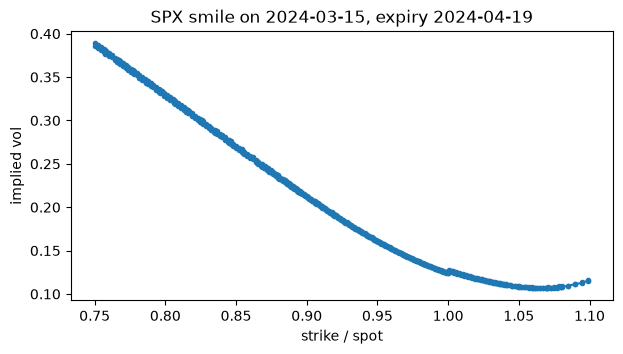

In [8]:
expiry = chain[chain.am_settlement == 1].exdate.min()  # the standard (AM-settled) monthly expiry
otm = chain[
    (chain.exdate == expiry)
    & (
        ((chain.cp_flag == "P") & (chain.moneyness < 1))
        | ((chain.cp_flag == "C") & (chain.moneyness >= 1))
    )
]
otm = otm[otm.moneyness.between(0.75, 1.1)].sort_values("moneyness")
ax = otm.plot(x="moneyness", y="impl_volatility", marker=".", legend=False, figsize=(7, 3.5))
ax.set(
    title=f"SPX smile on 2024-03-15, expiry {expiry:%Y-%m-%d}",
    xlabel="strike / spot",
    ylabel="implied vol",
);

## 5. Volatility surface: 30-day at-the-money implied vol

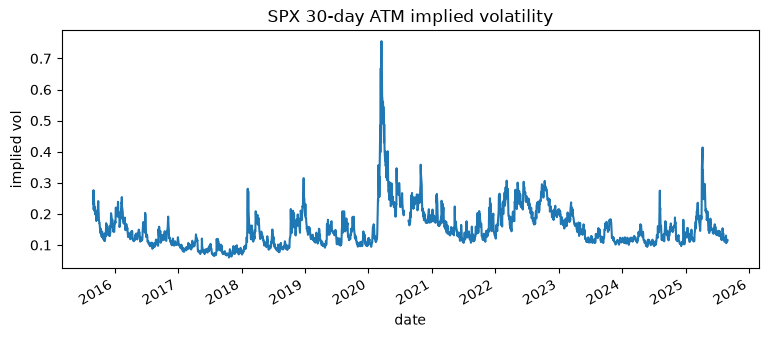

In [9]:
atm = qrd.get_vol_surface(days=30, delta=50, cp_flag="C").set_index("date")["impl_volatility"]
ax = atm.plot(figsize=(9, 3.5), title="SPX 30-day ATM implied volatility")
ax.set_ylabel("implied vol");

## 6. Beyond the US: the A/H share premium

The same API covers China A shares and the Hong Kong H shares of the same companies.

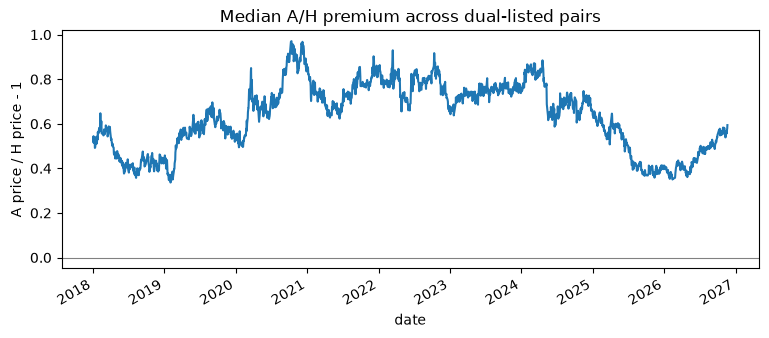

In [10]:
prem = qrd.cn_hk.ah_premium(start="2018-01-01")
ax = (
    prem.groupby("date")
    .premium.median()
    .plot(figsize=(9, 3.5), title="Median A/H premium across dual-listed pairs")
)
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("A price / H price - 1");

## 7. SQL with DuckDB

In [11]:
con = qrd.duckdb_connect(["us_stock_daily"], start="2025-01-01", end="2025-12-31")
con.sql("""
    select ticker, exp(sum(ln(1 + ret))) - 1 as ret_2025, max(mktcap) / 1e6 as max_mktcap_bn
    from us_stock_daily
    where share_type = 'NS' and security_sub_type = 'COM' and ret is not null
    group by ticker
    order by max_mktcap_bn desc
    limit 10
""").df()

,ticker,ret_2025,max_mktcap_bn
0,NVDA,0.389146,5032.107200
1,AAPL,0.090448,4228.844465
2,MSFT,0.155871,4028.869142
3,AMZN,0.052095,2715.314864
4,AVGO,0.506475,1957.890770
5,GOOGL,0.660020,1881.773920
6,GOOG,0.654262,1749.921480
7,META,0.130889,1713.479980
8,TSLA,0.113612,1629.252212
9,LLY,0.402351,1049.319517
